# CODE 3.2: Check the Windows

> **Goal:** check the two files of notebook 3.1 in a second, independent way before any model uses them.
>
> Notebook 3.1 computed all 47,491 windows at once with fast array tricks. Fast code can hide small mistakes, for example a window shifted by one tick. So here we take a sample of windows and rebuild them **slowly and simply, straight from the raw readings**, with different code. If both ways give the same numbers, we can trust the files.
>
> - **Input:** `data/processed/metropt3.parquet` (1.1), `results/time_split.csv` (1.2), `data/processed/windows.parquet` and `data/processed/grid.npz` (3.1).
> - **Output:** no files. Only checks, tables and two charts. At the end you should see **ALL CHECKS PASSED**.
>
> As before: sensor values are only shown for train and validation. For test windows, only PASS or FAIL is printed.

### The Two Files, in Short

> | File | What it is | Used by |
> | --- | --- | --- |
> | `windows.parquet` | the list of windows: one row per window, with `end`, `start`, `end_index`, `split` and the 46 summary numbers | Isolation Forest (the 46 numbers), and the LSTM (only `end_index` and `split`) |
> | `grid.npz` | the whole recording on the 10-second clock, scaled | the LSTM: notebook 4.2 cuts 360 ticks out of it for every window |
>
> Think of `grid.npz` as one long video, and of `windows.parquet` as a list of bookmarks in it, each with a report card of its hour. Isolation Forest only reads the report cards. The LSTM opens the video at each bookmark and watches the hour before it.

## Import Libraries & Variables

### Import Libraries

> - `os`: works with folders and file paths.
> - `numpy`, `pandas`: work with numbers, tables and times.
> - `matplotlib`: draws charts.

In [19]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### Variables

#### Folder Paths

> The inputs from notebooks 1.1, 1.2 and 3.1.

In [20]:
ROOT_DIR = os.getcwd()
while not os.path.isfile(os.path.join(ROOT_DIR, "requirements.txt")) and ROOT_DIR != os.path.dirname(ROOT_DIR):
    ROOT_DIR = os.path.dirname(ROOT_DIR)

PROCESSED_DIR = os.path.join(ROOT_DIR, "data", "processed")
PARQUET_FILE = os.path.join(PROCESSED_DIR, "metropt3.parquet")
SPLIT_FILE = os.path.join(ROOT_DIR, "results", "time_split.csv")
WINDOWS_FILE = os.path.join(PROCESSED_DIR, "windows.parquet")
GRID_FILE = os.path.join(PROCESSED_DIR, "grid.npz")
print("Project folder found:", os.path.basename(ROOT_DIR))

Project folder found: predictive-maintenance-metropt


#### Settings

> - The window settings and signal lists are the same as in notebook 3.1.
> - `SAMPLE_PER_PART`: how many random windows of each part we rebuild by hand.
> - `SEED`: makes the random sample the same every time.
> - `TOLERANCE`: the files store numbers as `float32` (about 7 digits), so two ways of computing may differ in the last digits. Differences below 0.001 count as equal.
> - `COMPARE_FEATURES`: four summary numbers we compare between February and March in a chart.
> - `HALF_OF_MARCH` and `HALVES_FEATURES`: we split March into two halves and compare six summary numbers, to see which changes last the whole month.
> - `NORMAL_DAY` and `MARCH_DAY`: two days we draw next to each other: a normal February day (the same day as in notebook 2.1) and 12 March.
> - `DAY_SIGNALS`: the three signals drawn for these two days, with their labels.

In [21]:
WINDOW_MINUTES = 60
STEP_MINUTES = 5
GRID_SECONDS = 10
MAX_AGE_SECONDS = 30
WINDOW_STEPS = WINDOW_MINUTES * 60 // GRID_SECONDS
FIRST_TIME = "2020-02-01 00:00:00"

ANALOG_COLUMNS = ["TP2", "TP3", "H1", "DV_pressure", "Reservoirs", "Oil_temperature", "Motor_current"]
DIGITAL_COLUMNS = ["COMP", "DV_eletric", "Towers", "MPG", "LPS", "Pressure_switch", "Oil_level", "Caudal_impulses"]
SIGNALS = ANALOG_COLUMNS + DIGITAL_COLUMNS
OIL_COLUMN = "Oil_temperature"
PUMP_COLUMN = "DV_eletric"
TANK_COLUMN = "Reservoirs"
LEVEL_COLUMNS = [column for column in ANALOG_COLUMNS if column != OIL_COLUMN]

SAMPLE_PER_PART = 30
SEED = 0
TOLERANCE = 0.001
COMPARE_FEATURES = ["pump_starts", "drop_bar_per_min", "rise_bar_per_min", "Oil_temperature_change"]
HALF_OF_MARCH = "2020-03-16 00:00:00"
HALVES_FEATURES = ["COMP_on_share", "pump_starts", "drop_bar_per_min", "TP3_max", "Oil_temperature_std", "rise_bar_per_min"]
NORMAL_DAY = "2020-02-12"
MARCH_DAY = "2020-03-12"
DAY_SIGNALS = {"Reservoirs": "Tank pressure (bar)", "DV_eletric": "Pump on (1) or off (0)", "Oil_temperature": "Oil temperature (°C)"}

## Functions

### Record a Check

> `check()` prints PASS or FAIL for one check and stores the result in `results`.

In [22]:
results = {}

def check(name, ok):
    results[name] = bool(ok)
    print(("PASS  " if ok else "FAIL  ") + name)

### Rebuild One Window from the Raw Readings

> `raw_window()` rebuilds one window the slow way, with pandas instead of the array tricks of notebook 3.1:
>
> 1. Make the 360 ticks of the window: every 10 seconds, ending at `end`.
> 2. Take only the raw readings of the last 61 minutes before `end`.
> 3. For each tick, find the latest reading at or before it, at most 30 seconds old (`merge_asof` with a `tolerance`).

In [23]:
def raw_window(df_sensors, end, window_minutes, grid_seconds, max_age_seconds, signals):
    ticks = pd.DataFrame({"tick": pd.date_range(end=end, periods=window_minutes * 60 // grid_seconds, freq=f"{grid_seconds}s").astype("datetime64[us]")})
    nearby = df_sensors[(df_sensors["timestamp"] > end - pd.Timedelta(minutes=window_minutes + 1)) & (df_sensors["timestamp"] <= end)]
    joined = pd.merge_asof(ticks, nearby, left_on="tick", right_on="timestamp", direction="backward",
                           tolerance=pd.Timedelta(seconds=max_age_seconds))
    return joined[signals].astype("float64")

### The 46 Numbers, the Slow Way

> `slow_features()` computes the same 46 summary numbers as notebook 3.1, but one window at a time, with plain pandas and a simple loop for the pump cycles, so it shares no code with notebook 3.1. Spreads use `ddof=0`, the same formula as numpy.

In [24]:
def slow_features(window, level_columns, oil_column, digital_columns, pump_column, tank_column, grid_seconds):
    row = {}
    for column in level_columns:
        row[f"{column}_mean"] = window[column].mean()
        row[f"{column}_std"] = window[column].std(ddof=0)
        row[f"{column}_min"] = window[column].min()
        row[f"{column}_max"] = window[column].max()
    oil = window[oil_column]
    row[f"{oil_column}_change"] = oil.iloc[-1] - oil.iloc[0]
    row[f"{oil_column}_range"] = oil.max() - oil.min()
    row[f"{oil_column}_std"] = oil.std(ddof=0)
    for column in digital_columns:
        row[f"{column}_on_share"] = window[column].mean()
        row[f"{column}_switches"] = window[column].diff().abs().sum()

    pumping, tank = window[pump_column].tolist(), window[tank_column].tolist()
    starts, drops, rises = 0, [], []
    for index in range(1, len(tank)):
        if pumping[index - 1] == 0 and pumping[index] == 1:
            starts += 1
        if pumping[index - 1] == 0 and pumping[index] == 0:
            drops.append(tank[index - 1] - tank[index])
        if pumping[index - 1] == 1 and pumping[index] == 1:
            rises.append(tank[index] - tank[index - 1])
    per_minute = 60 / grid_seconds
    row["pump_starts"] = starts
    row["drop_bar_per_min"] = sum(drops) / len(drops) * per_minute if drops else 0.0
    row["rise_bar_per_min"] = sum(rises) / len(rises) * per_minute if rises else 0.0
    return row

### One Window for the LSTM, Copied from 3.1

> `lstm_window()` is copied unchanged from notebook 3.1: it cuts 360 ticks out of the scaled grid and turns the oil temperature into a change.

In [25]:
def lstm_window(grid_scaled, end_index, window_steps, oil_index):
    window = grid_scaled[end_index - window_steps + 1:end_index + 1].copy()
    window[:, oil_index] -= window[0, oil_index]
    return window

### Scaling Numbers by Hand

> `scaling_numbers()` rebuilds the scaling numbers the slow way: it makes every 10-second tick from `start` up to (not including) `end`, finds the latest reading of each tick with `merge_asof`, drops the ticks without a reading, and returns the average and the spread of each column.

In [26]:
def scaling_numbers(df_sensors, start, end, grid_seconds, max_age_seconds, columns):
    ticks = pd.DataFrame({"tick": pd.date_range(start, end, freq=f"{grid_seconds}s", inclusive="left").astype("datetime64[us]")})
    joined = pd.merge_asof(ticks, df_sensors, left_on="tick", right_on="timestamp", direction="backward",
                           tolerance=pd.Timedelta(seconds=max_age_seconds)).dropna(subset=columns)
    values = joined[columns].astype("float64")
    return values.mean(), values.std(ddof=0)

## Load the Files

### Read Everything Back from Disk

> This notebook does not use anything that notebook 3.1 left in memory: it only reads the saved files.

In [27]:
df_sensors = pd.read_parquet(PARQUET_FILE)
df_windows = pd.read_parquet(WINDOWS_FILE)
with np.load(GRID_FILE) as saved:
    grid = {name: saved[name] for name in saved.files}
split_table = pd.read_csv(SPLIT_FILE).set_index("split")
FEATURE_COLUMNS = [column for column in df_windows.columns if column not in ["end", "start", "end_index", "split"]]

print(f"windows.parquet: {len(df_windows):,} windows, {len(FEATURE_COLUMNS)} summary numbers")
print("grid.npz holds:", list(grid))
print("Grid values:", grid["values"].shape, "(ticks, signals) | signals in order:", grid["signals"].tolist() == SIGNALS)

windows.parquet: 47,491 windows, 46 summary numbers
grid.npz holds: ['values', 'has_reading', 'tick_seconds', 'signals', 'scaled_columns', 'scale_mean', 'scale_std']
Grid values: (1841760, 15) (ticks, signals) | signals in order: True


## Check the List of Windows

### Shape and Order

> - Every window lasts exactly 60 minutes: from its first tick to its last tick is 59 minutes and 50 seconds, which makes 360 ticks.
> - Every window ends on a 5-minute mark, and no end appears twice.
> - `end_index` really points to the tick of `end` in the grid: tick number *n* is `FIRST_TIME` plus *n* times 10 seconds.
> - All ticks of every window have a reading in the saved grid.

In [28]:
length = df_windows["end"] - df_windows["start"]
tick_of_end = pd.Timestamp(FIRST_TIME) + pd.to_timedelta(df_windows["end_index"] * GRID_SECONDS, unit="s")
missing_so_far = np.concatenate([[0], np.cumsum(~grid["has_reading"])])
missing_in_window = missing_so_far[df_windows["end_index"] + 1] - missing_so_far[df_windows["end_index"] + 1 - WINDOW_STEPS]

check("every window lasts exactly 60 minutes (360 ticks)", (length == pd.Timedelta(seconds=(WINDOW_STEPS - 1) * GRID_SECONDS)).all())
check("every window ends on a 5-minute mark", (df_windows["end"].dt.second.eq(0) & df_windows["end"].dt.minute.mod(STEP_MINUTES).eq(0)).all())
check("the windows are in time order and no end appears twice", df_windows["end"].is_monotonic_increasing and df_windows["end"].is_unique)
check("end_index points to the tick of the window end", (tick_of_end == df_windows["end"]).all())
check("every tick of every window has a reading in the saved grid", (missing_in_window == 0).all())

PASS  every window lasts exactly 60 minutes (360 ticks)
PASS  every window ends on a 5-minute mark
PASS  the windows are in time order and no end appears twice
PASS  end_index points to the tick of the window end
PASS  every tick of every window has a reading in the saved grid


### The Parts, Checked Again

> Every window belongs to the part of its end, and no window may hold minutes of a later part. Here this is checked with the dates of `time_split.csv` and the `start` of each window.

In [29]:
validation_from = pd.Timestamp(split_table.loc["validation", "from"])
test_from = pd.Timestamp(split_table.loc["test", "from"])
parts = df_windows.groupby("split", observed=True).agg(windows=("end", "size"), earliest_start=("start", "min"), latest_end=("end", "max"))
display(parts)

check("train windows start and end in February", ((df_windows.loc[df_windows["split"] == "train", "start"] >= pd.Timestamp(FIRST_TIME))
                                                 & (df_windows.loc[df_windows["split"] == "train", "end"] < validation_from)).all())
check("validation windows end in March", ((df_windows.loc[df_windows["split"] == "validation", "end"] >= validation_from)
                                         & (df_windows.loc[df_windows["split"] == "validation", "end"] < test_from)).all())
check("test windows end in April or later", (df_windows.loc[df_windows["split"] == "test", "end"] >= test_from).all())

,windows,earliest_start,latest_end
split,,,
train,6790,2020-02-01 00:00:10,2020-02-28 23:55:00
validation,7194,2020-03-01 04:00:10,2020-03-31 23:55:00
test,33507,2020-03-31 23:00:10,2020-09-01 03:55:00


PASS  train windows start and end in February
PASS  validation windows end in March
PASS  test windows end in April or later


## Rebuild Windows by Hand

### A Random Sample of Each Part

> We pick `SAMPLE_PER_PART` random windows of each part, rebuild them from the raw readings with `raw_window()`, compute their 46 numbers with `slow_features()`, and compare with `windows.parquet`. For each part we print only the largest difference, so no test value is shown.

In [30]:
sample = df_windows.groupby("split", observed=True).sample(n=SAMPLE_PER_PART, random_state=SEED)
largest = {}
for part, rows in sample.groupby("split", observed=True):
    differences = []
    for row in rows.itertuples():
        rebuilt = raw_window(df_sensors=df_sensors, end=row.end, window_minutes=WINDOW_MINUTES, grid_seconds=GRID_SECONDS,
                             max_age_seconds=MAX_AGE_SECONDS, signals=SIGNALS)
        slow = slow_features(window=rebuilt, level_columns=LEVEL_COLUMNS, oil_column=OIL_COLUMN, digital_columns=DIGITAL_COLUMNS,
                             pump_column=PUMP_COLUMN, tank_column=TANK_COLUMN, grid_seconds=GRID_SECONDS)
        fast = df_windows.loc[row.Index, FEATURE_COLUMNS].astype("float64")
        differences.append(np.abs(pd.Series(slow)[FEATURE_COLUMNS] - fast).max())
    largest[part] = max(differences)
    print(f"{part:<11} {len(rows)} windows rebuilt | largest difference in any of the 46 numbers: {largest[part]:.6f}")
print()
check(f"the rebuilt windows give the same 46 numbers (difference below {TOLERANCE})", max(largest.values()) < TOLERANCE)

train       30 windows rebuilt | largest difference in any of the 46 numbers: 0.000001
validation  30 windows rebuilt | largest difference in any of the 46 numbers: 0.000001
test        30 windows rebuilt | largest difference in any of the 46 numbers: 0.000008

PASS  the rebuilt windows give the same 46 numbers (difference below 0.001)


### The Same Windows for the LSTM

> For the same sample, we scale the rebuilt readings by hand with the saved scaling numbers, turn the oil temperature into a change, and compare with what `lstm_window()` cuts out of `grid.npz`.

In [31]:
scale_mean, scale_std = grid["scale_mean"], grid["scale_std"]
oil_index = SIGNALS.index(OIL_COLUMN)
largest_lstm = 0.0
for row in sample.itertuples():
    rebuilt = raw_window(df_sensors=df_sensors, end=row.end, window_minutes=WINDOW_MINUTES, grid_seconds=GRID_SECONDS,
                         max_age_seconds=MAX_AGE_SECONDS, signals=SIGNALS).to_numpy()
    by_hand = rebuilt.copy()
    by_hand[:, :len(ANALOG_COLUMNS)] = (rebuilt[:, :len(ANALOG_COLUMNS)] - scale_mean) / scale_std
    by_hand[:, oil_index] -= by_hand[0, oil_index]
    from_grid = lstm_window(grid_scaled=grid["values"], end_index=row.end_index, window_steps=WINDOW_STEPS, oil_index=oil_index)
    largest_lstm = max(largest_lstm, np.abs(by_hand - from_grid).max())
print(f"{len(sample)} windows | largest difference in any of the 360 x 15 values: {largest_lstm:.6f}\n")
check(f"the LSTM input cut from the grid equals the one made by hand (difference below {TOLERANCE})", largest_lstm < TOLERANCE)

90 windows | largest difference in any of the 360 x 15 values: 0.000002

PASS  the LSTM input cut from the grid equals the one made by hand (difference below 0.001)


## Check the Scaling

### Rebuild the Scaling Numbers from February Alone

> The scaling numbers in `grid.npz` must come from February only. We rebuild them by hand twice: once from February ticks, and once from February and March together. The first must match the saved numbers; the second should not. That shows that no March number went into them.

In [32]:
february_mean, february_std = scaling_numbers(df_sensors=df_sensors, start=FIRST_TIME, end=validation_from, grid_seconds=GRID_SECONDS,
                                              max_age_seconds=MAX_AGE_SECONDS, columns=ANALOG_COLUMNS)
both_mean, both_std = scaling_numbers(df_sensors=df_sensors, start=FIRST_TIME, end=test_from, grid_seconds=GRID_SECONDS,
                                      max_age_seconds=MAX_AGE_SECONDS, columns=ANALOG_COLUMNS)
display(pd.DataFrame({"saved average": scale_mean, "February only": february_mean.values, "February + March": both_mean.values},
                     index=ANALOG_COLUMNS).round(4))

check("the saved averages match February alone", np.allclose(scale_mean, february_mean, atol=TOLERANCE))
check("the saved spreads match February alone", np.allclose(scale_std, february_std, atol=TOLERANCE))
check("the saved averages do not match February + March", not np.allclose(scale_mean, both_mean, atol=TOLERANCE))

,saved average,February only,February + March
TP2,0.5375,0.5375,1.0427
TP3,8.9621,8.9621,9.0029
H1,8.3983,8.3983,7.9196
DV_pressure,-0.0156,-0.0156,0.0084
Reservoirs,8.9641,8.9641,9.0035
Oil_temperature,56.3095,56.3095,59.3447
Motor_current,1.2447,1.2447,1.6778


PASS  the saved averages match February alone
PASS  the saved spreads match February alone
PASS  the saved averages do not match February + March


> **What we see:** the saved numbers are the February numbers. With March added, some averages move, the oil temperature most of all, because the oil was warmer in March.

## February Against March

### Which Summary Numbers Change from February to March?

> The models learn from February windows, and the alarm limit is set on March windows. So it helps to know now which of the 46 numbers are different in March. For each number we compare its middle value (median) in the two months, measured in February spreads: 0 means "the same", 1 means "one February spread higher".

In [33]:
february = df_windows.loc[df_windows["split"] == "train", FEATURE_COLUMNS]
march = df_windows.loc[df_windows["split"] == "validation", FEATURE_COLUMNS]
spread = february.std().replace(0, np.nan)
shift = ((march.median() - february.median()) / spread).dropna().sort_values(key=np.abs, ascending=False)
table = pd.DataFrame({"February median": february.median()[shift.index], "March median": march.median()[shift.index], "shift (in February spreads)": shift})
display(table.head(10).round(3))
print("Summary numbers that never change in February (spread 0), left out of the table:", spread[spread.isna()].index.tolist())
print("Shift of the four numbers in the chart below:", shift.reindex(COMPARE_FEATURES).astype("float64").round(2).to_dict())

,February median,March median,shift (in February spreads)
Oil_temperature_std,1.562,4.417,5.901
Oil_temperature_range,7.075,15.325,3.409
rise_bar_per_min,1.201,0.913,-3.018
TP3_max,10.112,10.158,2.438
DV_pressure_min,-0.020,-0.026,-2.424
Reservoirs_max,10.112,10.158,2.398
H1_max,10.100,10.152,2.363
TP2_mean,0.536,0.919,2.108
COMP_on_share,0.939,0.897,-2.083
MPG_on_share,0.939,0.897,-2.083


Summary numbers that never change in February (spread 0), left out of the table: ['LPS_on_share', 'LPS_switches', 'Oil_level_on_share', 'Oil_level_switches', 'Caudal_impulses_on_share', 'Caudal_impulses_switches']
Shift of the four numbers in the chart below: {'pump_starts': 1.7, 'drop_bar_per_min': 1.25, 'rise_bar_per_min': -3.02, 'Oil_temperature_change': -0.02}


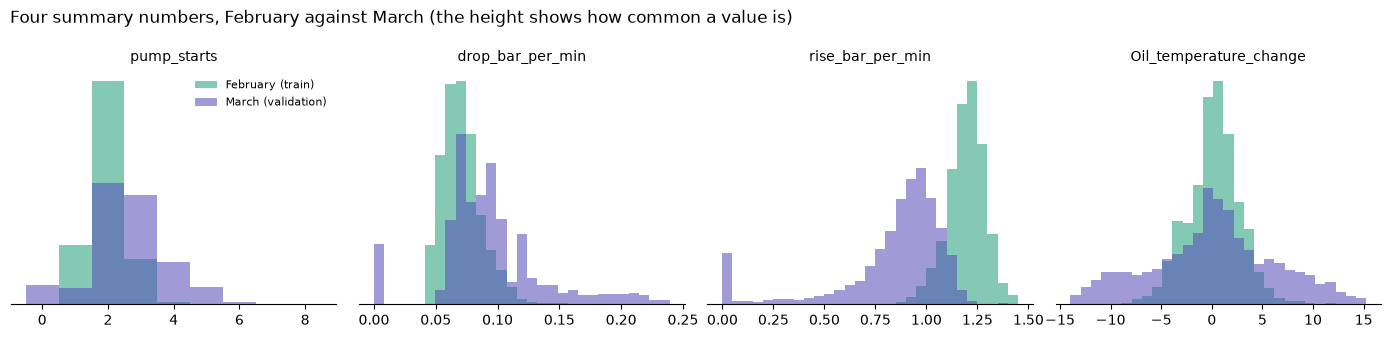

Windows with no resting moment in the whole hour (drop_bar_per_min = 0): February 0, March 414


In [34]:
fig, axes = plt.subplots(1, len(COMPARE_FEATURES), figsize=(14, 3.4))
for ax, column in zip(axes, COMPARE_FEATURES):
    low, high = np.percentile(pd.concat([february[column], march[column]]), [0.5, 99.5])
    bins = np.linspace(low, high, 30) if column != "pump_starts" else np.arange(-0.5, max(february[column].max(), march[column].max()) + 1.5)
    ax.hist(february[column], bins=bins, density=True, alpha=0.55, color="#1D9E75", label="February (train)")
    ax.hist(march[column], bins=bins, density=True, alpha=0.55, color="#534AB7", label="March (validation)")
    ax.set_title(column, fontsize=10)
    ax.set_yticks([])
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Four summary numbers, February against March (the height shows how common a value is)", x=0.01, ha="left")
plt.tight_layout()
plt.show()

print(f"Windows with no resting moment in the whole hour (drop_bar_per_min = 0): "
      f"February {int((february['drop_bar_per_min'] == 0).sum())}, March {int((march['drop_bar_per_min'] == 0).sum())}")

> **What we see:**
>
> - The numbers that change most are about the **oil temperature** and the **pumping**. In March the oil temperature swings much more within an hour (its spread and range), the tank pressure rises more slowly while pumping, the tanks are filled a little higher (the highest pressures), and the compressor pumps a larger share of the time (`TP2_mean`, `COMP_on_share`; `COMP` is on when the compressor is **not** pumping).
> - A big shift is not always a big change in real units. The highest pressure moved by only a few hundredths of a bar, but in February it hardly ever varies, so even this small move counts as more than two spreads. A model that learned February will notice such small moves too.
> - In the chart, March windows more often have 3 or more pump starts, the pressure drops faster while resting, and it rises more slowly while pumping. The oil temperature change keeps its middle value but spreads much wider.
> - `drop_bar_per_min` can only be measured while the pump rests. In some March windows the pump never rested, so notebook 3.1 filled in 0: that is the lonely bar at 0 in the second chart. February has no such window. The section "Hours in March That February Never Had" below looks at them closely.

### Early March or the Whole Month?

> Notebook 2.1 found that the compressor pumped more often from the start of March. Here we check which changes stay for the whole month: we split March into two halves at `HALF_OF_MARCH` and compare the middle values of six summary numbers.

In [35]:
first_half = df_windows.loc[(df_windows["split"] == "validation") & (df_windows["end"] < pd.Timestamp(HALF_OF_MARCH)), FEATURE_COLUMNS]
second_half = df_windows.loc[(df_windows["split"] == "validation") & (df_windows["end"] >= pd.Timestamp(HALF_OF_MARCH)), FEATURE_COLUMNS]
halves = pd.DataFrame({"February": february[HALVES_FEATURES].median(), "March 1-15": first_half[HALVES_FEATURES].median(),
                       "March 16-31": second_half[HALVES_FEATURES].median()})
print(f"Windows: February {len(february):,}, March 1-15 {len(first_half):,}, March 16-31 {len(second_half):,}")
display(halves.astype("float64").round(3))

Windows: February 6,790, March 1-15 3,249, March 16-31 3,945


,February,March 1-15,March 16-31
COMP_on_share,0.939,0.881,0.917
pump_starts,2.000,3.000,2.000
drop_bar_per_min,0.069,0.118,0.073
TP3_max,10.112,10.220,10.140
Oil_temperature_std,1.562,4.409,4.421
rise_bar_per_min,1.201,0.929,0.899


> **What we see:** the extra pumping is mostly in the **first half** of March: more pump starts, a faster pressure drop while resting, less time without pumping, and a higher top pressure. In the second half these numbers come back closer to February. The wider oil temperature swings and the slower rise while pumping stay for the **whole month**.

### Oil Temperature: Level Against Change

> Decision 3 of notebook 2.1 gave the models the oil temperature as a *change* within the window, not as its level. Here we measure what that decision avoids. The level of a window is the average oil temperature of its 360 ticks; it is computed here only for this comparison, and is not one of the 46 numbers.

In [36]:
oil_scaled = np.nan_to_num(grid["values"][:, oil_index].astype("float64"))
running_sum = np.concatenate([[0], np.cumsum(oil_scaled)])
ends = df_windows["end_index"].to_numpy()
oil_level = (running_sum[ends + 1] - running_sum[ends + 1 - WINDOW_STEPS]) / WINDOW_STEPS * scale_std[oil_index] + scale_mean[oil_index]
level = pd.Series(oil_level, index=df_windows.index)

level_shift = (level[march.index].median() - level[february.index].median()) / level[february.index].std()
change_shift = shift[f"{OIL_COLUMN}_change"]
print(f"Oil temperature level:  February median {level[february.index].median():.1f} °C, March median {level[march.index].median():.1f} °C, "
      f"shift {level_shift:.2f} February spreads")
print(f"Oil temperature change: shift {change_shift:.2f} February spreads")

Oil temperature level:  February median 56.7 °C, March median 61.9 °C, shift 1.82 February spreads
Oil temperature change: shift -0.02 February spreads


> **What we see:** the oil temperature **level** moved by almost two February spreads from February to March, while the middle value of the **change** stayed where it was. A model that had learned the February level would find many March hours unusual only because the oil was warmer. Why it was warmer, more work or warmer weather, the data cannot tell, because it has no outside temperature. With the change, this slow drift stays away from the models. The change itself does swing more widely in March (see the chart above): within an hour, the oil heats up and cools down more than in February.

## Hours in March That February Never Had

### Pumping Without a Break

> In some March windows the pump never rested (see the chart above). Here we find out when that happened. Windows that follow each other every 5 minutes belong to one **stretch** of pumping without a break. A stretch lasted at least from the start of its first window until the end of its last window.
>
> To compare, we also measure the longest stretch of pumping without a break in February, on the 10-second grid: we mark every February tick where the pump is on, find where each run of such ticks starts and stops, and take the longest run.

In [37]:
whole_hour = df_windows.loc[(df_windows["split"] == "validation") & (df_windows["drop_bar_per_min"] == 0)]
new_stretch = whole_hour["end"].diff() != pd.Timedelta(minutes=STEP_MINUTES)
stretches = whole_hour.groupby(new_stretch.cumsum()).agg(first_end=("end", "min"), until=("end", "max"), windows=("end", "size"))
stretches["pumping from"] = stretches["first_end"] - pd.Timedelta(minutes=WINDOW_MINUTES)
stretches["hours without a break (at least)"] = ((stretches["until"] - stretches["pumping from"]) / pd.Timedelta(hours=1)).round(1)
display(stretches[["pumping from", "until", "hours without a break (at least)", "windows"]].reset_index(drop=True))

pump_index = SIGNALS.index(PUMP_COLUMN)
february_ticks = int((validation_from - pd.Timestamp(FIRST_TIME)) / pd.Timedelta(seconds=GRID_SECONDS))
pumping = np.concatenate([[0], (grid["values"][:february_ticks, pump_index] == 1).astype(int), [0]])
run_starts, run_stops = np.flatnonzero(np.diff(pumping) == 1), np.flatnonzero(np.diff(pumping) == -1)
longest_february = (run_stops - run_starts).max() * GRID_SECONDS / 60

print(f"{len(stretches)} stretches, {len(whole_hour)} windows, the longest stretch {stretches['hours without a break (at least)'].max():.1f} hours")
print(f"Longest stretch of pumping without a break in February: {longest_february:.1f} minutes")
print(f"Pump on in these March windows: at least {whole_hour['DV_eletric_on_share'].min():.1%} of the ticks")
print(f"Tank pressure rise while pumping: at most {whole_hour['rise_bar_per_min'].max():.3f} bar per minute in these March windows, "
      f"at least {february['rise_bar_per_min'].min():.3f} in every February window")
print(f"Oil temperature level (middle value): {level[whole_hour.index].median():.1f} °C in these March windows, {level[february.index].median():.1f} °C in February")

,pumping from,until,hours without a break (at least),windows
0,2020-03-06 21:45:00,2020-03-06 23:00:00,1.2,4
1,2020-03-12 00:20:00,2020-03-12 11:50:00,11.5,127
2,2020-03-27 07:15:00,2020-03-27 11:35:00,4.3,41
3,2020-03-28 07:25:00,2020-03-28 08:50:00,1.4,6
4,2020-03-28 23:10:00,2020-03-29 19:45:00,20.6,236


5 stretches, 414 windows, the longest stretch 20.6 hours
Longest stretch of pumping without a break in February: 4.2 minutes
Pump on in these March windows: at least 99.7% of the ticks
Tank pressure rise while pumping: at most 0.099 bar per minute in these March windows, at least 0.735 in every February window
Oil temperature level (middle value): 75.7 °C in these March windows, 56.7 °C in February


> **What we see:** the windows without a rest come from a few long stretches, the longest almost a full day, while in February the pump never ran for more than a few minutes in one go. In these hours the pump hardly ever stopped, and still the tank pressure **barely rose**: far slower than in any February window. It is like filling a bucket with a hole in it: you keep pouring, but the water level does not go up. Meanwhile the oil stayed much warmer than in February.

### One Normal Day Next to 12 March

> The chart puts a normal February day next to 12 March, the day of the second stretch. For each day it shows the tank pressure, the pump (on or off) and the oil temperature, straight from the raw readings. Where the recording has a gap of more than 30 seconds, the line stops at the last reading before the gap instead of being drawn across it.

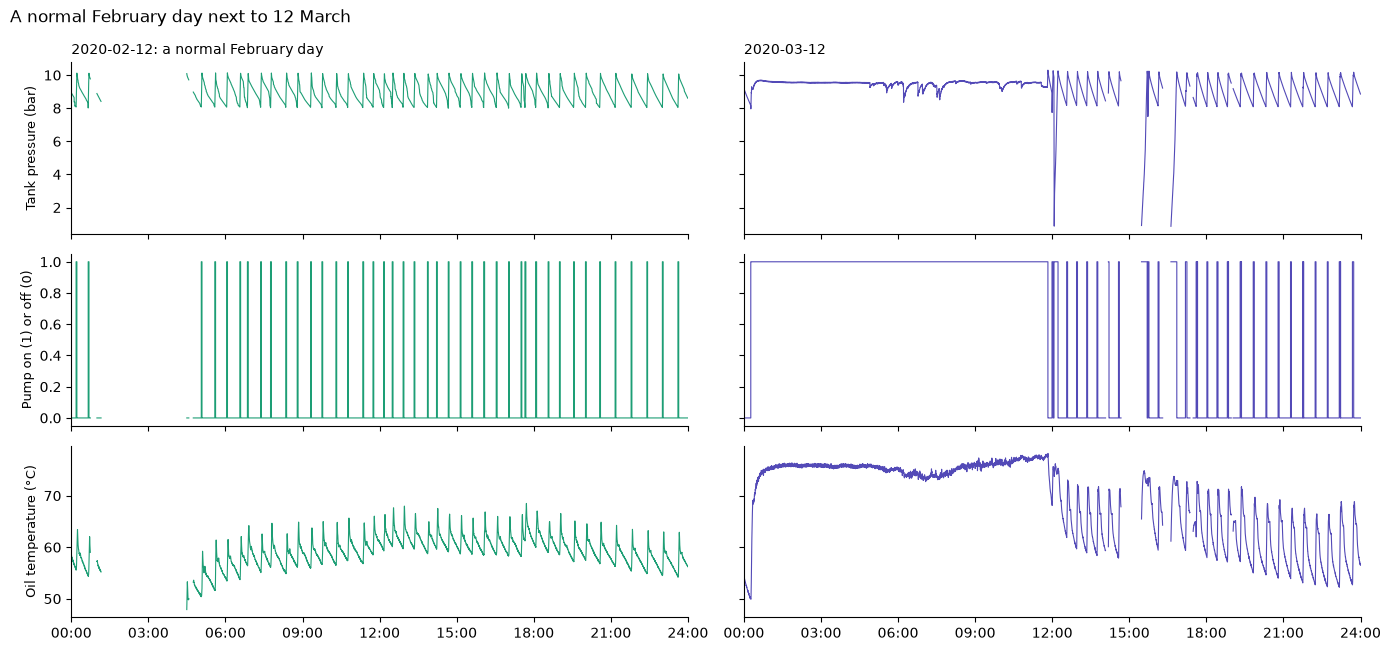

In [38]:
fig, axes = plt.subplots(len(DAY_SIGNALS), 2, figsize=(14, 6.6), sharex="col", sharey="row")
for col, (day, color, title) in enumerate([(NORMAL_DAY, "#1D9E75", f"{NORMAL_DAY}: a normal February day"), (MARCH_DAY, "#534AB7", f"{MARCH_DAY}")]):
    start = pd.Timestamp(day)
    readings = df_sensors[(df_sensors["timestamp"] >= start) & (df_sensors["timestamp"] < start + pd.Timedelta(days=1))]
    hours = (readings["timestamp"] - start) / pd.Timedelta(hours=1)
    before_gap = readings["timestamp"].diff().shift(-1) > pd.Timedelta(seconds=MAX_AGE_SECONDS)
    for row, (column, label) in enumerate(DAY_SIGNALS.items()):
        ax = axes[row, col]
        ax.plot(hours, readings[column].astype("float64").mask(before_gap), color=color, linewidth=0.8,
                drawstyle="steps-post" if column == PUMP_COLUMN else "default")
        ax.set_xlim(0, 24)
        ax.set_xticks(range(0, 25, 3), [f"{hour:02d}:00" for hour in range(0, 25, 3)])
        if col == 0:
            ax.set_ylabel(label, fontsize=9)
        for side in ["top", "right"]:
            ax.spines[side].set_visible(False)
    axes[0, col].set_title(title, fontsize=10, loc="left")
fig.suptitle("A normal February day next to 12 March", x=0.01, ha="left")
plt.tight_layout()
plt.show()

> **What we see:** on the normal day the tank pressure saws up and down all day, the pump runs in short bursts, and the oil temperature waves gently. On 12 March the pump runs **without a break** from soon after midnight until around noon: the tank pressure stays flat instead of rising, and the oil stays hot. In the afternoon the recording has gaps, and the tank pressure falls far below its normal range.

### Signals That Never Move in February

> Six summary numbers never change in February (see the list printed under the first table of "February Against March"). They belong to three on/off signals. Here we check what these signals do in March: for each one, how many March windows differ from its February value, and on which days of March.

In [39]:
never_moving = [column[:-len("_on_share")] for column in spread[spread.isna()].index if column.endswith("_on_share")]
rows = []
for column in never_moving:
    february_value = int(february[f"{column}_on_share"].iloc[0])
    differs = march.index[march[f"{column}_on_share"] != february_value]
    rows.append({"signal": column, "value in every February window": february_value, "March windows that differ": len(differs),
                 "share of March windows": f"{len(differs) / len(march):.0%}",
                 "days of March": ", ".join(df_windows.loc[differs, "end"].dt.day.astype(str).unique())})
display(pd.DataFrame(rows).set_index("signal"))

,value in every February window,March windows that differ,share of March windows,days of March
signal,,,,
LPS,0,36,1%,"11, 12, 14, 15, 16, 29, 31"
Oil_level,1,90,1%,"1, 2, 5, 6, 10, 11, 12"
Caudal_impulses,1,2434,34%,"1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11"


> **What we see:** all three signals **do move in March**. `LPS` switches on, which means the pressure fell below 7 bar, on several days. `Oil_level` changes on some days in the first part of the month. `Caudal_impulses` stays 0 for the first eleven days of March, about a third of all March windows.

### What This Means for the Next Steps

> - **No failure is reported in March.** Whether these hours were an unreported problem or an unusual way of running the train, the data cannot tell. They are clearly not normal February behaviour, so a model trained on February will find them very unusual.
> - **The alarm limit (notebook 5.1)** is set on March, under the idea that March shows normal operation. Alarms in these hours would count as false alarms and push the limit up, which makes the models less sensitive. Notebook 5.1 decides how these hours count, before any test result is seen.
> - **Signals that never move in February:** Isolation Forest cannot use them, because a tree can only split on a number that varies. The LSTM would learn "this signal is always the same" and react to every change in it, for example during the first eleven days of March, when `Caudal_impulses` stays 0. Notebooks 4.1 and 4.2 decide which signals the models get.

## Result

### Final Result

> If every check passed, both files of notebook 3.1 are correct and ready for the models. If a check failed, its name is printed.

In [40]:
failed = [name for name, ok in results.items() if not ok]
if results and not failed:
    print(f"ALL CHECKS PASSED ({len(results)} checks)")
else:
    print(f"{len(failed)} of {len(results)} checks FAILED:")
    for name in failed:
        print("  -", name)

ALL CHECKS PASSED (13 checks)


## Summary

> - Every window lasts exactly 60 minutes, ends on a 5-minute mark, has a reading at every tick, and sits in the right part.
> - Random windows of every part, rebuilt slowly from the raw readings with different code, give the same 46 summary numbers and the same LSTM input as the files of notebook 3.1.
> - The scaling numbers come from February alone: adding March would change them.
> - From February to March, the numbers about the oil temperature and the pumping change the most: the oil temperature swings more within an hour, the tank fills more slowly, and the compressor pumps a larger share of the time. The extra pumping is mostly in the first half of March; the oil swings and the slow filling last the whole month.
> - March has hours that February never had: a few long stretches in which the pump ran without a break while the tank pressure barely rose, and three signals (`LPS`, `Oil_level`, `Caudal_impulses`) that never move in February but do move in March. No failure is reported in March.
> - The models learn February, and the alarm limit is set on March. Notebooks 4.1 and 4.2 decide which signals the models get, and notebook 5.1 decides how these unusual March hours count when the limit is set.
>
> **Next:** `notebooks/4_modeling/4.1_train_isolation_forest.ipynb`